In [2]:
%pip install -U xarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 13.7 MB/s  0:00:00
  Attempting uninstall: xarray
    Found existing installation: xarray 2024.1.0
    Uninstalling xarray-2024.1.0:
      Successfully uninstalled xarray-2024.1.0
Note: you may need to restart the kernel to use updated packages.


In [1]:
import icechunk
import xarray as xr

# source.coop data proxy — serves public data without credentials.
# The org name ("englacial") is used as the S3 bucket; the repo path follows.
SOURCE_COOP_ENDPOINT = "https://data.source.coop"
ORG_NAME = "englacial"

def open_icechunk_repo(path: str): 
    storage = icechunk.s3_storage(
        bucket=ORG_NAME,
        prefix=path,
        endpoint_url=SOURCE_COOP_ENDPOINT,
        anonymous=True,
        force_path_style=True,
    )
    return icechunk.Repository.open(storage)

def open_store(path: str) ->  xr.Dataset:

    repo = open_icechunk_repo(path)

    # branch="main" fetches the most recent version of the data
    session = repo.readonly_session(branch="main")

    # zarr_format=3 enables Zarr v3 sharding (outer shards + inner chunks)
    return xr.open_zarr(session.store, consolidated=False, zarr_format=3)

 # realizations array + seed_id/y/x coords
realizations_dataset = open_store("demogorgn/icechunk/realizations.icechunk")  

# bed + y/x coords
mask_dataset = open_store("demogorgn/icechunk/antarctica_fast_flow_mask_50m.icechunk")


  2026-10-13T16:24:01.241754Z  WARN aws_config::imds::region: failed to load region from IMDS, err: failed to load IMDS session token: dispatch failure: timeout: HTTP read timeout occurred after 1s: timed out (FailedToLoadToken(FailedToLoadToken { source: DispatchFailure(DispatchFailure { source: ConnectorError { kind: Timeout, source: HttpTimeoutError { kind: "HTTP read", duration: 1s }, connection: Unknown } }) }))
    at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/aws-config-1.8.15/src/imds/region.rs:66

  2026-10-13T16:24:04.021174Z  WARN aws_config::imds::region: failed to load region from IMDS, err: failed to load IMDS session token: dispatch failure: io error: client error (Connect): tcp connect error: No route to host (os error 65) (FailedToLoadToken(FailedToLoadToken { source: DispatchFailure(DispatchFailure { source: ConnectorError { kind: Io, source: hyper_util::client::legacy::Error(Connect, ConnectError("tcp connect error", 169.254.169.254:80, Os { c

In [3]:
# Bounding box in EPSG:3031 metres
X_MIN, X_MAX = -1085_250, -972_250
Y_MAX, Y_MIN =  -918_250,  -977_250   # descending — pass max first

realizations = realizations_dataset["realizations"]

subset = realizations.sel(
    x=slice(X_MIN, X_MAX),
    y=slice(Y_MAX, Y_MIN),   # y descending
)
print(f"Subset shape: {subset.shape}")   # (100, n_y, n_x)

# Ensemble mean and std over all 100 realizations
mean_elev = subset.mean(dim="seed_id").compute()
std_elev  = subset.std(dim="seed_id").compute()

Subset shape: (100, 119, 227)


In [4]:
# Select realizations 72 by label
subset_3 = realizations.sel(
    x=slice(X_MIN, X_MAX),
    y=slice(Y_MAX, Y_MIN),
    seed_id=[72],
)

# Or select a contiguous range with slice
subset_first20 = realizations.sel(
    x=slice(X_MIN, X_MAX),
    y=slice(Y_MAX, Y_MIN),
    seed_id=slice(0, 19),
)

In [5]:
import numpy as np

# Load the same spatial window from the mask store
fast_flow_mask_window = mask_dataset["fast_flow_mask"].sel(
    x=slice(X_MIN, X_MAX),
    y=slice(Y_MAX, Y_MIN),
)

# Align mask to the realizations grid (handles any minor float coord differences)
fast_flow_mask_aligned = fast_flow_mask_window.interp_like(subset, method="nearest")

# Mask: keep only pixels where fast_flow_mask == 1 (fast-flow pixels)
masked_subset = subset.where(fast_flow_mask_aligned == 1)

mean_masked = masked_subset.mean(dim="seed_id").compute()
std_masked  = masked_subset.std(dim="seed_id").compute()

# Count of valid pixels per location
n_valid = (~np.isnan(masked_subset)).sum(dim="seed_id").compute()


/opt/anaconda3/envs/geostats2026/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


In [6]:
n_pts   = 40
track_x = xr.DataArray(np.linspace(X_MIN, X_MAX, n_pts), dims="points")
track_y = xr.DataArray(np.full(n_pts, (Y_MIN + Y_MAX) / 2.0), dims="points")

profile = realizations.interp(x=track_x, y=track_y, method="linear").compute()
# shape: (100, 40) — all realizations at each sample point

ens_mean = profile.mean("seed_id")
ens_std  = profile.std("seed_id")


In [19]:
import netCDF4 as nc_lib
import numpy as np

OUT_PATH = "./smooth_test_area_3_real.nc"

# ── Define the subset ────────────────────────────────────────────────────────
X_MIN, X_MAX = -1085_250, -972_250
Y_MAX, Y_MIN =  -918_250, -977_250
SEED_IDS     = list([0, 1, 2])   # all 100; narrow to e.g. [0, 1, 2] for a quick test

realizations = realizations_dataset["realizations"]
subset = realizations.sel(
    x=slice(X_MIN, X_MAX),
    y=slice(Y_MAX, Y_MIN),
    seed_id=SEED_IDS,
).compute()

x_vals      = subset.x.values.astype("float32")
y_vals      = subset.y.values.astype("float32")
seed_id_vals = subset.seed_id.values.astype("int64")
n_seeds, ny, nx = subset.shape
n_seeds, ny, nx = subset.shape
print("subset shape:", n_seeds, ny, nx)

# ── Write NetCDF ─────────────────────────────────────────────────────────────
with nc_lib.Dataset(OUT_PATH, "w", format="NETCDF4") as dst:
    dst.createDimension("seed_id", n_seeds)
    dst.createDimension("y", ny)
    dst.createDimension("x", nx)
    
    # Coordinate variables
    v = dst.createVariable("seed_id", "i8", ("seed_id",)); v[:] = seed_id_vals
    v = dst.createVariable("y",  "f4", ("y",));  v[:] = y_vals;  v.units = "metres"
    v = dst.createVariable("x",  "f4", ("x",));  v[:] = x_vals;  v.units = "metres"

    # Main data variable — chunked for efficient row-oriented reads
    data_var = dst.createVariable(
        "realizations", "f4", ("seed_id", "y", "x"),
        chunksizes=(1, 119, 128),
        zlib=True, complevel=4,
        fill_value=np.nan,
    )
    data_var[:] = subset.values
    data_var.grid_mapping = "crs"
    data_var.long_name    = "bed elevation ensemble"
    data_var.units        = "m"

    dst.Conventions = "CF-1.8"
    dst.source      = "s3://us-west-2.opendata.source.coop/englacial/demogorgn/icechunk/realizations.icechunk"

print(f"Written: {OUT_PATH}  ({ny} × {nx}, {n_seeds} realizations)")


subset shape: 3 119 227
Written: ./smooth_test_area_3_real.nc  (119 × 227, 3 realizations)


In [20]:
#try to visualize
#import data
ds = xr.open_dataset('smooth_test_area_3_real.nc')

In [21]:
ds
#max_val_y = ds.max(dim="y")
#print(max_val_y)

<xarray.Dataset> Size: 326kB
Dimensions:       (seed_id: 3, y: 119, x: 227)
Coordinates:
  * seed_id       (seed_id) int64 24B 0 1 2
  * y             (y) float32 476B -9.182e+05 -9.188e+05 ... -9.772e+05
  * x             (x) float32 908B -1.085e+06 -1.085e+06 ... -9.722e+05
Data variables:
    realizations  (seed_id, y, x) float32 324kB ...
Attributes:
    Conventions:  CF-1.8
    source:       s3://us-west-2.opendata.source.coop/englacial/demogorgn/ice...

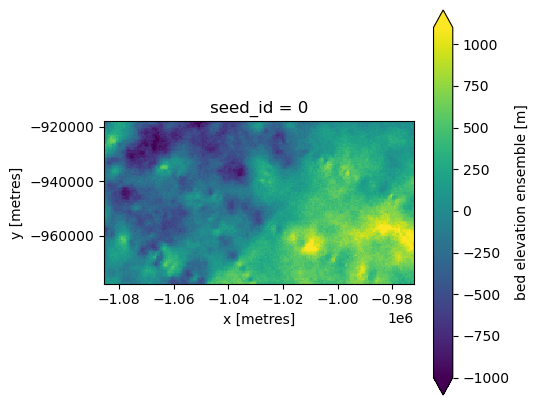

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
ds.realizations.sel(seed_id=0).plot(ax=ax, cmap="viridis", vmin = -1000, vmax = 1100)
ax.set_aspect("equal")  # x/y are in meters (projected), so keep equal aspect
plt.show()

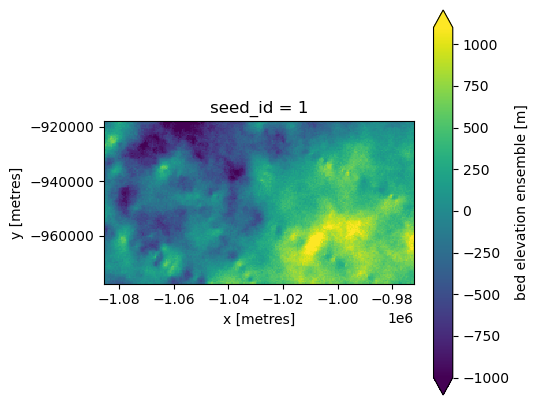

In [25]:
fig, ax = plt.subplots(figsize=(5, 5))
ds.realizations.sel(seed_id=1).plot(ax=ax, cmap="viridis", vmin = -1000, vmax = 1100)
ax.set_aspect("equal")  # x/y are in meters (projected), so keep equal aspect
plt.show()

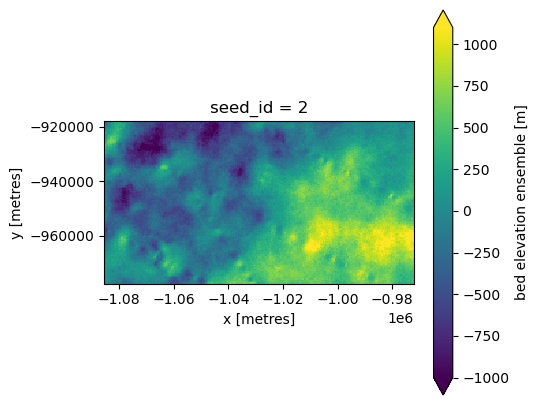

In [26]:
fig, ax = plt.subplots(figsize=(5, 5))
ds.realizations.sel(seed_id=2).plot(ax=ax, cmap="viridis", vmin = -1000, vmax = 1100)
ax.set_aspect("equal")  # x/y are in meters (projected), so keep equal aspect
plt.show()